# Лабораторная работа №2

ФИО: Вояга Даниил Максимович  
Группа: БИВТ-24-СП-3

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №6

Что необходимо сделать:  
**В общих чертах просто провести EDA** (но обычно это не бывает просто)
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. **Найти** в таблице (из исходных данных) название своего датасета
2. **Описать** кратко постановку задачи, что от вас хотят. Какие есть переменные. Целевое событие непрерывно (предсказываем число от -$\infty$ до $\infty$) либо дискретно (предсказываем класс из конечного множества вариантов, например 0 или 1, или какое-то число в диапазоне [0; 10])
3. Построить распределение целевой переменной в виде гистограммы, сделать промежуточные выводы (обратите внимание на однородоность распределения и возможный дисбаланс). Посчитайте количество уникальных значений целевой переменной.
4. Выведите основные статистики по переменным в датасете (для этого есть готовый метод в pandas, он считает count, min, max, mean, 25%, 50% и пр.). Это делается **одним** методом (вы его знаете).
5. Выведите основную информацию по датасету (сколько всего колонок, каких они типов, сколько в них non-null элементов). Это делается **одним** методом (вы его знаете).
6. Посчитайте количество пропусков (NaN, Null, null, None) элементов во всех колонках. Предположите, почему эти пропуски могли возникнуть, и как их можно было бы заменить. 
7. Постройте гистограммы 5 любых признаков (из множества `X`, или как оно изначально у нас называется `data.data`). Если видите какое-то смещение, несимметричность и прочее, опишите это словами в ноутбуке.
8. Постройте графики зависимости 5 любых (на ваш выбор) переменных от целевой переменной (если переменных меньше, чем 5, то сделайте столько, сколько получится). Сделайте вывод, можно ли использовать эти переменные для прогнозирования целевой переменной (иначе говоря, есть ли какая-то взаимосвязь между y-переменной и X-переменной)  
9. _extra_ (необязательно). Посмотрите на зависимость двух переменных одновременно от целевой переменной. То есть по оси OX должна быть переменная $X_{n}$, по оси OY -- переменная $X_{k}$. И у вас будет две кривые (два облака точек) в разрезе целевой переменной. Либо вы можете построить похожее для категориальных признаков, но необходимо будет прочитать про heatmap. 

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

## 0. Импорт библиотек и данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
path_to_dataset = "../data/aug_train.csv"
data = pd.read_csv(path_to_dataset, sep=",")  # файл разделён запятыми
data.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


## 1. Название датасета

**HR Analytics: Job Change of Data Scientists** - файл `aug_train.csv`
Источник: [Kaggle](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists?select=aug_train.csv)

## 2. Описание постановки задачи

Компания, работающая в сфере Big Data и Data Science, проводит обучающие курсы и хочет нанимать специалистов из числа тех, кто их успешно прошёл. Многие записываются на курсы, но не все потом хотят работать в компании. Задача - **по данным о кандидате (демография, образование, опыт, текущая работа) предсказать, будет ли он искать новую работу** (то есть уйдёт ли в эту компанию). Это помогает сократить расходы на обучение и лучше планировать курсы.

**Переменные:**

| Переменная | Описание | Тип |
|---|---|---|
| `enrollee_id` | уникальный ID кандидата | идентификатор, не признак |
| `city` | код города | категориальный (123 значения) |
| `city_development_index` | индекс развития города (0-1) | числовой |
| `gender` | пол | категориальный |
| `relevent_experience` | есть ли релевантный опыт | бинарный |
| `enrolled_university` | тип обучения в университете сейчас | категориальный |
| `education_level` | уровень образования | порядковый |
| `major_discipline` | направление образования | категориальный |
| `experience` | общий стаж в годах (`<1`, `1`...`20`, `>20`) | порядковый (хранится строкой) |
| `company_size` | размер текущей компании | порядковый |
| `company_type` | тип текущей компании | категориальный |
| `last_new_job` | лет с прошлой смены работы (`never`, `1`...`4`, `>4`) | порядковый (хранится строкой) |
| `training_hours` | сколько часов обучения пройдено | числовой |
| **`target`** | **0 - не ищет новую работу, 1 - ищет** | **целевая** |

**Целевое событие дискретно**: `target` принимает только два значения (0 и 1), значит это задача **бинарной классификации**.

## 3. Распределение целевой переменной

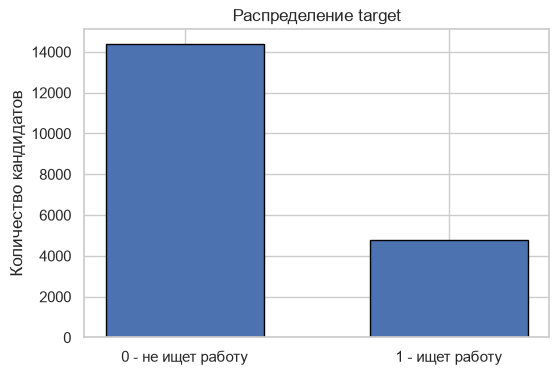

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(data["target"], bins=[-0.5, 0.5, 1.5], rwidth=0.6, edgecolor="black")
ax.set_xticks([0, 1], ["0 - не ищет работу", "1 - ищет работу"])
ax.set_ylabel("Количество кандидатов")
ax.set_title("Распределение target")
plt.show()

In [4]:
print("Уникальных значений target:", data["target"].nunique())
pd.DataFrame({
    "количество": data["target"].value_counts(),
    "доля": data["target"].value_counts(normalize=True).round(3),
})

Уникальных значений target: 2


,количество,доля
target,,
0.0,14381,0.751
1.0,4777,0.249


**Выводы:**
- У целевой переменной **2 уникальных значения** (0 и 1) - бинарная классификация.
- Распределение **неоднородное, есть дисбаланс классов**: 75% кандидатов (14 381) не ищут работу и только 25% (4 777) ищут, соотношение примерно 3:1.
- Из-за дисбаланса модель, которая всегда отвечает «0», уже получит accuracy 75%, поэтому accuracy - плохая метрика. Лучше смотреть на precision/recall, F1 или ROC-AUC, делить выборку со стратификацией (`stratify=y`) и, возможно, использовать веса классов или ресэмплинг.

## 4. Основные статистики по переменным

In [5]:
data.describe()

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


`describe()` по умолчанию считает статистики только для числовых колонок, а их здесь всего 4, причём `enrollee_id` - это просто ID, а `target` - метка класса (её среднее 0.249 и есть доля единиц).
- `city_development_index` от 0.448 до 0.949, медиана 0.903 больше среднего 0.829 - распределение скошено влево (большинство кандидатов из развитых городов).
- `training_hours` от 1 до 336, среднее 65 заметно больше медианы 47, а 75% значений не превышают 88 - длинный хвост вправо.

## 5. Основная информация по датасету

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 2.

- В датасете **19 158 строк и 14 колонок**.
- Типы: 2 вещественных (`city_development_index`, `target`), 2 целочисленных (`enrollee_id`, `training_hours`), остальные 10 - строковые (категориальные).
- `experience` и `last_new_job` по смыслу числовые, но хранятся строками из-за значений `<1`, `>20`, `never`, `>4` - для анализа их нужно перевести в числа.
- `target` хранится как `float`, хотя принимает только 0 и 1.
- Non-null меньше 19 158 у 8 колонок - в них есть пропуски (подробнее в п. 6).

## 6. Пропуски в данных

In [7]:
missing = pd.DataFrame({
    "пропусков": data.isna().sum(),
    "доля, %": (data.isna().mean() * 100).round(1),
})
missing.sort_values("пропусков", ascending=False)

,пропусков,"доля, %"
company_type,6140,32.0
company_size,5938,31.0
gender,4508,23.5
major_discipline,2813,14.7
education_level,460,2.4
last_new_job,423,2.2
enrolled_university,386,2.0
experience,65,0.3
enrollee_id,0,0.0
city,0,0.0


Проверим пару гипотез о том, откуда берутся пропуски:

In [8]:
# У кого пропущено направление образования?
data.loc[data["major_discipline"].isna(), "education_level"].value_counts(dropna=False)

education_level
High School       2017
NaN                460
Primary School     308
Graduate            22
Masters              6
Name: count, dtype: int64

In [9]:
# Компания: пропуски в размере и типе обычно идут вместе
both_missing = data["company_size"].isna() & data["company_type"].isna()
print("Пропущены и company_size, и company_type:", both_missing.sum())

# Доля ищущих работу среди тех, у кого признак пропущен, и среди остальных
pd.DataFrame({
    col: data.groupby(data[col].isna())["target"].mean()
    for col in ["company_size", "company_type", "gender", "major_discipline"]
}).rename(index={False: "значение есть", True: "пропуск"}).round(3)

Пропущены и company_size, и company_type: 5360


,company_size,company_type,gender,major_discipline
значение есть,0.179,0.184,0.231,0.259
пропуск,0.406,0.388,0.308,0.195


**Выводы по пропускам** (всего пропуски в 8 колонках из 14):

| Колонка | Пропусков | Почему могли возникнуть | Чем заменить |
|---|---|---|---|
| `company_type` | 6 140 (32%) | кандидат сейчас не работает или не указал компанию; в 5 360 случаях пропущен и `company_size` | отдельной категорией `"Unknown"` |
| `company_size` | 5 938 (31%) | то же самое | отдельной категорией `"Unknown"` |
| `gender` | 4 508 (23.5%) | не захотели указывать пол (необязательное поле) | категорией `"Unknown"` (модой `Male` нельзя - это исказит данные) |
| `major_discipline` | 2 813 (14.7%) | структурный пропуск: 2 785 из 2 813 - это кандидаты со школьным образованием (`High School`, `Primary School`) или без указанного образования, у них просто нет профиля | значением `"No Major"` / `"Not applicable"` |
| `education_level` | 460 (2.4%) | не заполнили анкету | модой (`Graduate`) или `"Unknown"` |
| `last_new_job` | 423 (2.2%) | не заполнили | модой (`1`) или `"Unknown"` |
| `enrolled_university` | 386 (2%) | не заполнили | модой (`no_enrollment`) |
| `experience` | 65 (0.3%) | не заполнили | медианой стажа или удалить строки (их очень мало) |

**Важно:** пропуски здесь не случайные. Среди кандидатов без информации о компании работу ищут около 40%, а среди остальных - около 18%. Поэтому для `company_*` и `gender` лучше не заполнять пропуск модой, а выделять отдельную категорию: сам факт пропуска несёт информацию о целевой переменной.

## 7. Гистограммы признаков

Числовых признаков в датасете всего два (`city_development_index`, `training_hours`), поэтому переведём порядковые `experience` и `last_new_job` в числа: `<1` → 0, `>20` → 21, `never` → 0, `>4` → 5.

In [10]:
data["experience_num"] = data["experience"].replace({"<1": "0", ">20": "21"}).astype(float)
data["last_new_job_num"] = data["last_new_job"].replace({"never": "0", ">4": "5"}).astype(float)
data[["experience", "experience_num", "last_new_job", "last_new_job_num"]].head()

,experience,experience_num,last_new_job,last_new_job_num
0,>20,21.0,1,1.0
1,15,15.0,>4,5.0
2,5,5.0,never,0.0
3,<1,0.0,never,0.0
4,>20,21.0,4,4.0


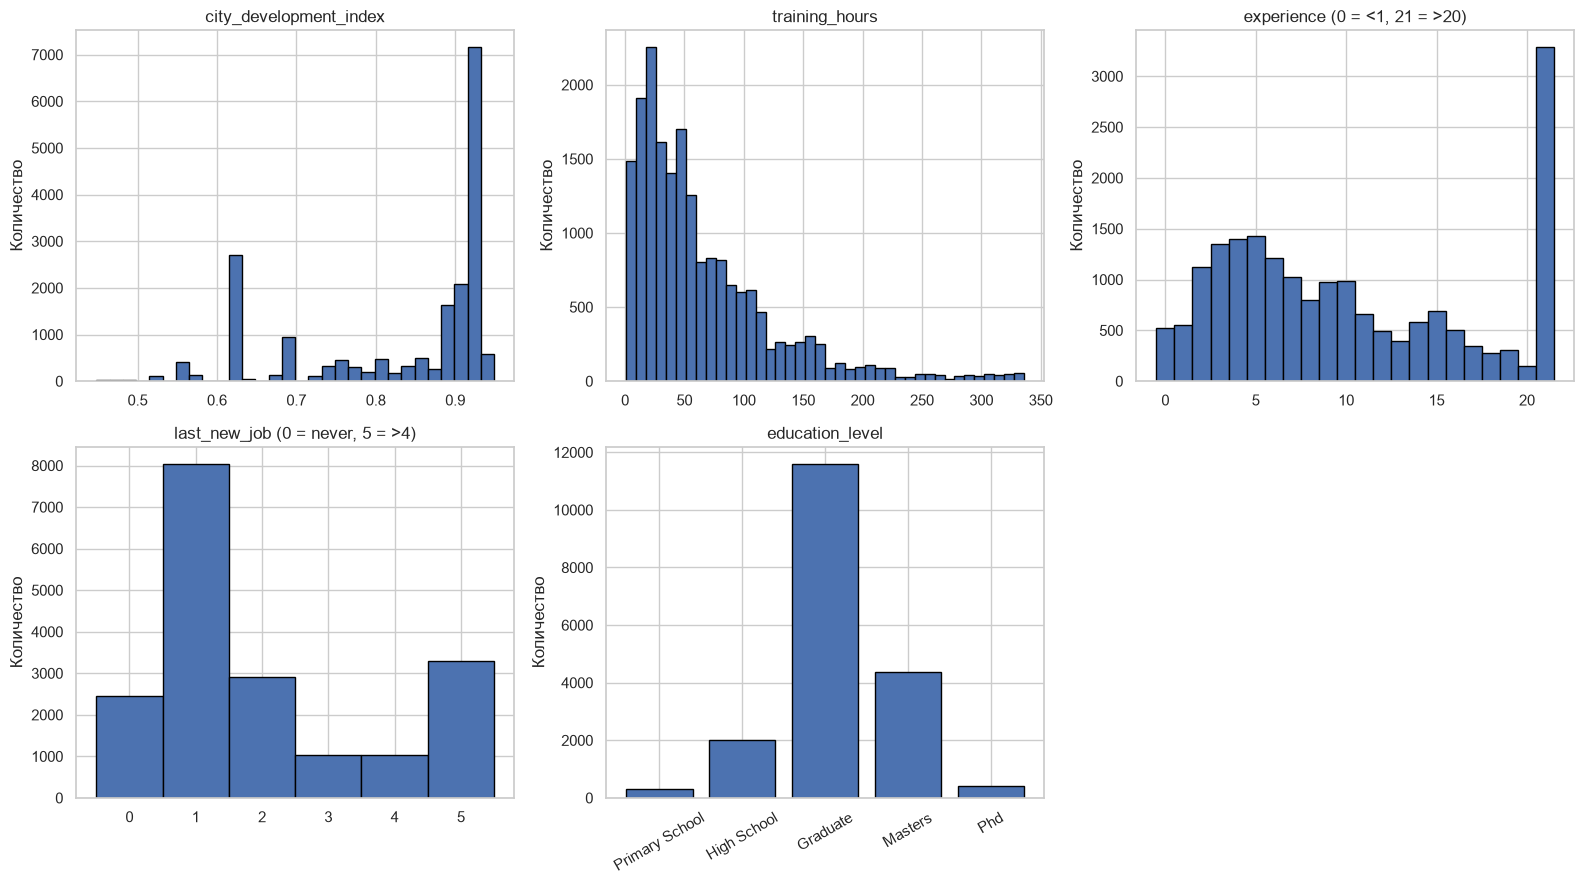

In [11]:
education_order = ["Primary School", "High School", "Graduate", "Masters", "Phd"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

axes[0].hist(data["city_development_index"], bins=30, edgecolor="black")
axes[0].set_title("city_development_index")

axes[1].hist(data["training_hours"], bins=40, edgecolor="black")
axes[1].set_title("training_hours")

axes[2].hist(data["experience_num"].dropna(), bins=np.arange(-0.5, 22.5, 1), edgecolor="black")
axes[2].set_title("experience (0 = <1, 21 = >20)")

axes[3].hist(data["last_new_job_num"].dropna(), bins=np.arange(-0.5, 6.5, 1), edgecolor="black")
axes[3].set_title("last_new_job (0 = never, 5 = >4)")

counts = data["education_level"].value_counts().reindex(education_order)
axes[4].bar(counts.index, counts.values, edgecolor="black")
axes[4].set_title("education_level")
axes[4].tick_params(axis="x", rotation=30)

axes[5].axis("off")
for ax in axes[:5]:
    ax.set_ylabel("Количество")
plt.tight_layout()
plt.show()

In [12]:
data[["city_development_index", "training_hours", "experience_num", "last_new_job_num"]].skew().round(2).rename("асимметрия (skew)")

city_development_index   -1.00
training_hours            1.82
experience_num            0.41
last_new_job_num          0.80
Name: асимметрия (skew), dtype: float64

**Выводы:**
- **`city_development_index`** - распределение несимметричное, скошено влево (skew ≈ -1) и **неоднородное**: два острых пика. Пик около 0.92 - это крупные города (`city_103`, 4 355 человек, и другие с тем же индексом), пик около 0.62 - один город `city_21` (2 702 человека). То есть значения признака во многом определяются несколькими большими городами.
- **`training_hours`** - сильная **правосторонняя асимметрия** (skew ≈ 1.8): большинство прошло до 100 часов, но есть длинный хвост до 336. Для линейных моделей такой признак полезно логарифмировать.
- **`experience`** - в целом скошен вправо (больше людей со стажем 2-7 лет), но есть **аномальный пик на значении 21**: это категория `>20` (3 286 человек), в которую «схлопнулся» весь хвост. Это артефакт того, как записаны данные, а не реальная особенность.
- **`last_new_job`** - мода на 1 году (8 040 человек, больше 40%), распределение скошено вправо, и снова пик на краю (`>4`) из-за объединения значений.
- **`education_level`** - сильный перекос в сторону `Graduate` (около 60%), `Phd` и `Primary School` - редкие категории (около 2% каждая).

## 8. Зависимость переменных от целевой переменной

Целевая переменная бинарная, поэтому для числовых признаков удобно сравнить распределения в двух классах (boxplot), а для категориальных - посмотреть долю ищущих работу (`target = 1`) в каждой категории.

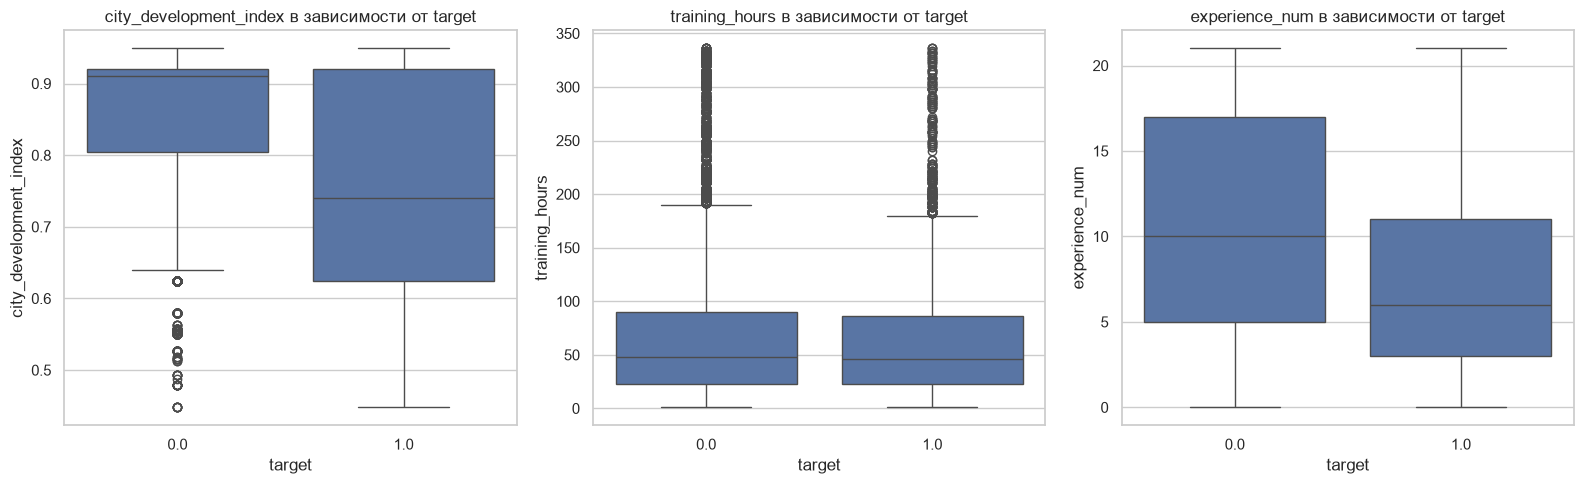

,city_development_index,training_hours,experience_num
target,,,
0.0,0.91,48.0,10.0
1.0,0.74,46.0,6.0


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["city_development_index", "training_hours", "experience_num"]):
    sns.boxplot(data=data, x="target", y=col, ax=ax)
    ax.set_title(f"{col} в зависимости от target")
plt.tight_layout()
plt.show()

data.groupby("target")[["city_development_index", "training_hours", "experience_num"]].median()

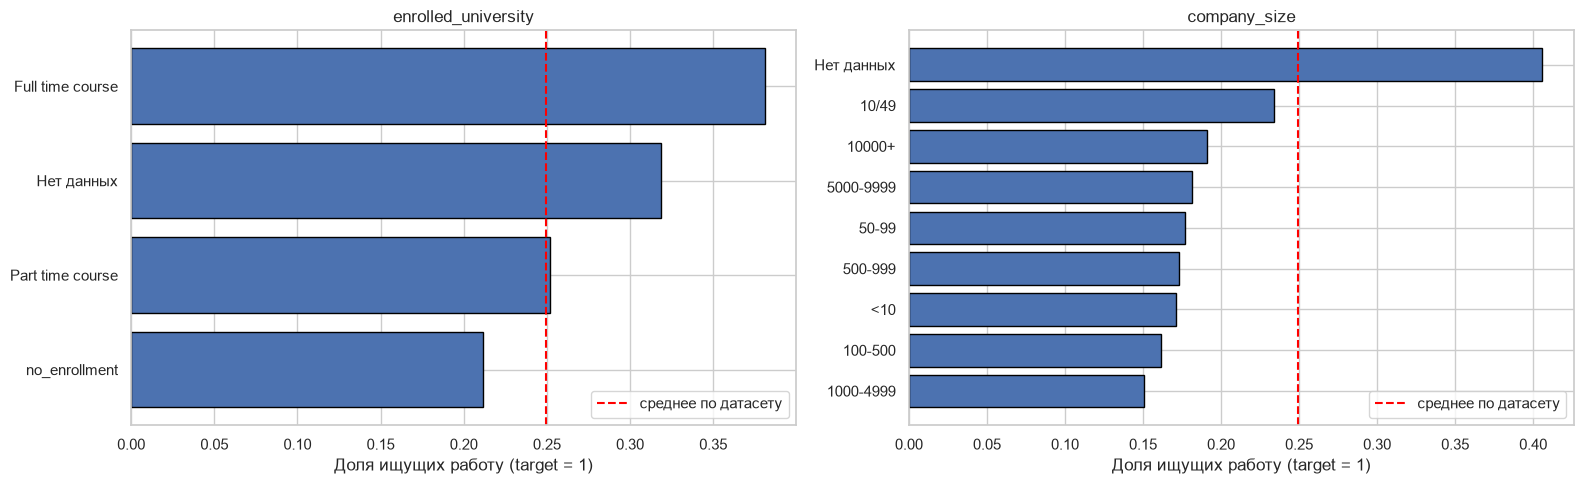

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ["enrolled_university", "company_size"]):
    rate = data.groupby(data[col].fillna("Нет данных"))["target"].mean().sort_values()
    ax.barh(rate.index, rate.values, edgecolor="black")
    ax.axvline(data["target"].mean(), color="red", linestyle="--", label="среднее по датасету")
    ax.set_xlabel("Доля ищущих работу (target = 1)")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Корреляция числовых признаков с target
data[["city_development_index", "training_hours", "experience_num", "last_new_job_num", "target"]].corr()["target"].round(3)

city_development_index   -0.342
training_hours           -0.022
experience_num           -0.177
last_new_job_num         -0.083
target                    1.000
Name: target, dtype: float64

**Выводы:**
- **`city_development_index`** - **самая сильная связь** с целевой переменной (корреляция ≈ -0.34). Медиана у ищущих работу 0.74, у остальных 0.91: чем менее развит город, тем чаще человек хочет сменить работу. В городах с индексом ниже 0.7 работу ищут около половины кандидатов. Признак точно полезен для прогноза.
- **`training_hours`** - **связи практически нет**: медианы 46 и 48 часов, корреляция ≈ -0.02, «ящики» почти совпадают. Сам по себе признак для прогноза бесполезен.
- **`experience`** - связь есть (корреляция ≈ -0.18): у ищущих работу медианный стаж 6 лет против 10 у остальных. Среди людей со стажем до года работу ищут около 45%, со стажем больше 20 лет - около 15%. Признак полезен.
- **`enrolled_university`** - студенты очной формы ищут работу заметно чаще (38%), чем те, кто не учится (21%). Признак полезен.
- **`company_size`** - для любого известного размера компании доля ищущих примерно одинаковая (15-23%), зато среди тех, у кого компания не указана, - 41%. Значит, полезен в первую очередь сам факт пропуска (скорее всего, человек сейчас не работает), а не размер компании.

Итого: для прогноза стоит использовать `city_development_index`, `experience`, `enrolled_university` и индикатор пропуска в `company_size`, а `training_hours` в одиночку почти ничего не даёт.

## 9. _extra_: зависимость двух переменных одновременно от целевой

**Числовые признаки:** по OX - `experience`, по OY - `city_development_index`, цвет - `target`. Стаж целочисленный, поэтому добавим небольшой случайный сдвиг (jitter), иначе точки сольются в вертикальные линии.

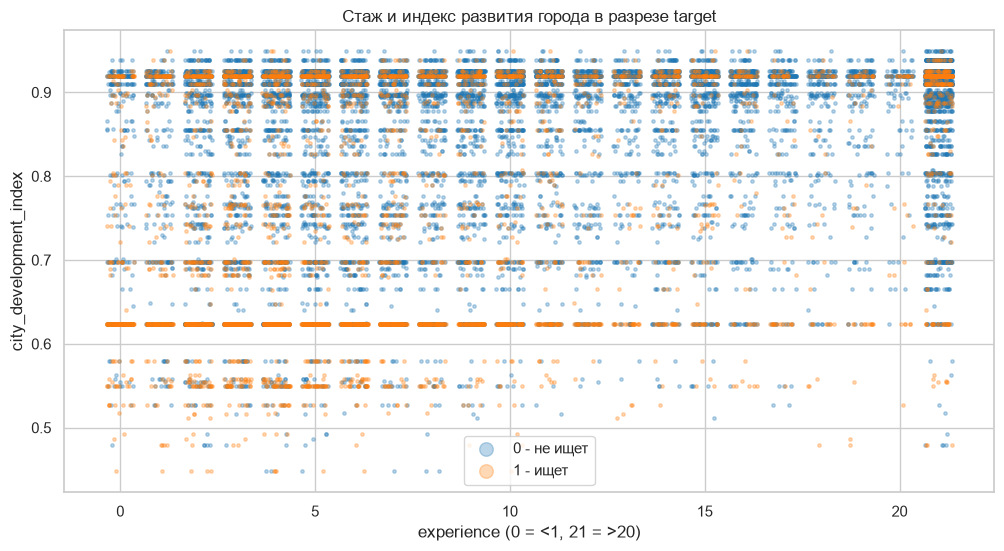

In [19]:
rng = np.random.default_rng(42)
plot_data = data.dropna(subset=["experience_num"])
jitter = rng.uniform(-0.35, 0.35, len(plot_data))

fig, ax = plt.subplots(figsize=(12, 6))
for value, color, label in [(0, "tab:blue", "0 - не ищет"), (1, "tab:orange", "1 - ищет")]:
    part = plot_data["target"] == value
    ax.scatter(plot_data.loc[part, "experience_num"] + jitter[part.to_numpy()],
               plot_data.loc[part, "city_development_index"],
               s=6, alpha=0.3, color=color, label=label)
ax.set_xlabel("experience (0 = <1, 21 = >20)")
ax.set_ylabel("city_development_index")
ax.set_title("Стаж и индекс развития города в разрезе target")
ax.legend(markerscale=4)
plt.show()

In [17]:
low_cdi = data["city_development_index"] < 0.7
print("Индекс < 0.7 и стаж <= 5 лет:  доля ищущих =", round(data.loc[low_cdi & (data["experience_num"] <= 5), "target"].mean(), 3))
print("Индекс >= 0.7 и стаж > 10 лет: доля ищущих =", round(data.loc[~low_cdi & (data["experience_num"] > 10), "target"].mean(), 3))

Индекс < 0.7 и стаж <= 5 лет:  доля ищущих = 0.551
Индекс >= 0.7 и стаж > 10 лет: доля ищущих = 0.143


Оранжевые точки («ищут работу») заметно гуще в нижней части графика (индекс < 0.7, особенно горизонтальная полоса 0.62 - это `city_21`) и в левой части (малый стаж). Сверху справа преобладают синие точки, хотя из-за наложения оранжевые там тоже видны, поэтому точнее посмотреть на доли. Если оба условия выполняются одновременно, эффект усиливается: при индексе < 0.7 и стаже до 5 лет работу ищут 55% кандидатов, а при индексе ≥ 0.7 и стаже больше 10 лет - всего 14%.

**Категориальные признаки:** heatmap доли ищущих работу для пар `education_level` × `enrolled_university`.

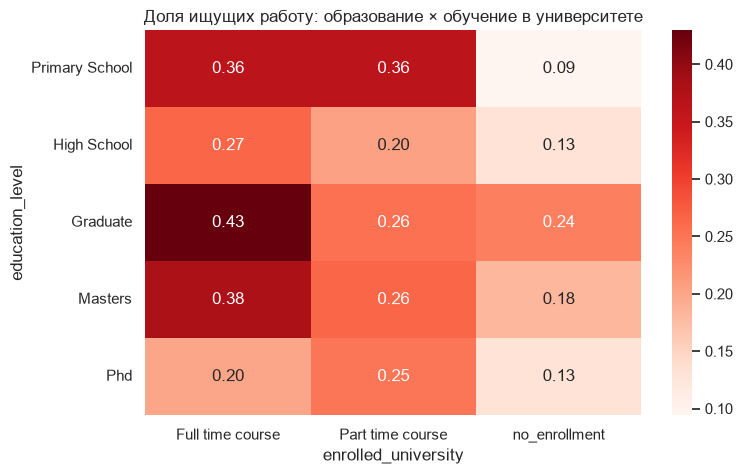

In [18]:
pivot = data.pivot_table(index="education_level", columns="enrolled_university",
                         values="target", aggfunc="mean").reindex(education_order)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds", ax=ax)
ax.set_title("Доля ищущих работу: образование × обучение в университете")
plt.show()

На всех уровнях образования те, кто сейчас учится (особенно очно), ищут работу чаще тех, кто не учится. Максимум у выпускников (`Graduate`), которые сейчас учатся очно, - 43%. Минимум у тех, кто не учится: 9% для `Primary School` и 13% для `High School` и `Phd`. Ячейки `Phd` и `Primary School` с учёбой в университете построены всего на 11-33 людях, так что их значения ненадёжны. Признаки дополняют друг друга, поэтому их комбинация может быть полезна модели.

## Итоги

- Задача - бинарная классификация (будет ли кандидат искать новую работу), классы несбалансированы 75/25.
- В данных много пропусков (до 32% в колонках о компании), и они не случайные: пропуск информации о компании сам по себе связан с поиском работы.
- Самые информативные признаки: `city_development_index`, `experience`, `enrolled_university` и факт отсутствия данных о компании. `training_hours` почти не связан с целевой переменной.
- Перед обучением модели нужно перевести `experience`, `last_new_job`, `company_size` в числа, закодировать категориальные признаки и учесть дисбаланс классов.